# Lot A — Exploration et analyse du dataset Online Retail

1. Qualité des données brutes (ce qu'il faut nettoyer)
2. Bilan du nettoyage
3. Analyse exploratoire : pays, produits, saisonnalité, heures de pointe

Les figures sont enregistrées dans `docs/captures/` pour le rapport.

> Lancer d'abord `python -m scripts.download_data` puis `python -m producer.prepare_data`.

In [1]:
import sys, json
from pathlib import Path
import os
if Path.cwd().name == "notebooks":   # on se place à la racine du projet
    os.chdir(Path.cwd().parent)
sys.path.append(str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from config import settings

FIG = Path("docs/captures"); FIG.mkdir(parents=True, exist_ok=True)
VIOLET = "#6C4CFF"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. Données brutes

In [2]:
brut = pd.read_excel(settings.RAW_DATA, dtype={"InvoiceNo": str, "StockCode": str})
print(brut.shape)
brut.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
qualite = pd.DataFrame({
    "valeurs manquantes": brut.isna().sum(),
    "% manquant": (brut.isna().mean() * 100).round(1),
})
qualite

,valeurs manquantes,% manquant
InvoiceNo,0,0.0
StockCode,0,0.0
Description,1454,0.3
Quantity,0,0.0
InvoiceDate,0,0.0
UnitPrice,0,0.0
CustomerID,135080,24.9
Country,0,0.0


In [4]:
annul = brut["InvoiceNo"].astype(str).str.startswith("C")
print("Doublons exacts            :", brut.duplicated().sum())
print("Factures annulées (lignes) :", annul.sum())
print("Quantités négatives        :", (brut["Quantity"] < 0).sum())
print("Prix <= 0                  :", (brut["UnitPrice"] <= 0).sum())
print("CustomerID manquant        :", brut["CustomerID"].isna().sum())
print("Période                    :", brut["InvoiceDate"].min(), "→", brut["InvoiceDate"].max())

Doublons exacts            : 5268
Factures annulées (lignes) : 9288
Quantités négatives        : 10624
Prix <= 0                  : 2517
CustomerID manquant        : 135080
Période                    : 2010-12-01 08:26:00 → 2011-12-09 12:50:00


In [5]:
# Codes qui ne sont pas des produits (frais de port, ajustements…)
codes = brut["StockCode"].astype(str).str.upper()
brut[~codes.str.match(r"^\d{5}")].groupby(codes)["Description"].first().head(20)

StockCode
AMAZONFEE                         AMAZON FEE
B                            Adjust bad debt
BANK CHARGES                    Bank Charges
C2                                  CARRIAGE
CRUK                         CRUK Commission
D                                   Discount
DCGS0003                 BOXED GLASS ASHTRAY
DCGS0004          HAYNES CAMPER SHOULDER BAG
DCGS0055                                None
DCGS0057                                None
DCGS0066P                               None
DCGS0067                                ebay
DCGS0068                                ebay
DCGS0069               OOH LA LA DOGS COLLAR
DCGS0070               CAMOUFLAGE DOG COLLAR
DCGS0071                                None
DCGS0072                                None
DCGS0073                                ebay
DCGS0074                                None
DCGS0076        SUNJAR LED NIGHT NIGHT LIGHT
Name: Description, dtype: object

## 2. Bilan du nettoyage

In [6]:
stats = json.loads(Path("docs/nettoyage_stats.json").read_text(encoding="utf-8"))
pd.Series(stats, name="valeur").to_frame()

,valeur
lignes_brutes,541909
doublons_supprimes,5268
sans_description,1454
prix_nul_ou_negatif,1058
codes_non_produits,2893
quantite_negative_hors_annulation,0
lignes_finales,531236
dont_annulations,8668
dont_sans_client,131580
nb_factures,23195


In [7]:
df = pd.read_csv(settings.CLEAN_DATA, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str},
                 parse_dates=["InvoiceDate"])
df["Montant"] = df["Quantity"] * df["UnitPrice"]
df["Annulation"] = df["InvoiceNo"].str.startswith("C")
ventes = df[~df["Annulation"]]
print(f"CA total : {ventes['Montant'].sum():,.0f} £  |  {ventes['InvoiceNo'].nunique():,} factures  |  "
      f"panier moyen : {ventes.groupby('InvoiceNo')['Montant'].sum().mean():.2f} £  |  "
      f"taux d'annulation : {df.loc[df['Annulation'], 'InvoiceNo'].nunique() / df['InvoiceNo'].nunique():.1%}")

CA total : 10,247,905 £  |  19,773 factures  |  panier moyen : 518.28 £  |  taux d'annulation : 14.8%


## 3. Analyse exploratoire
### Chiffre d'affaires par pays

Part du Royaume-Uni : 85.1%


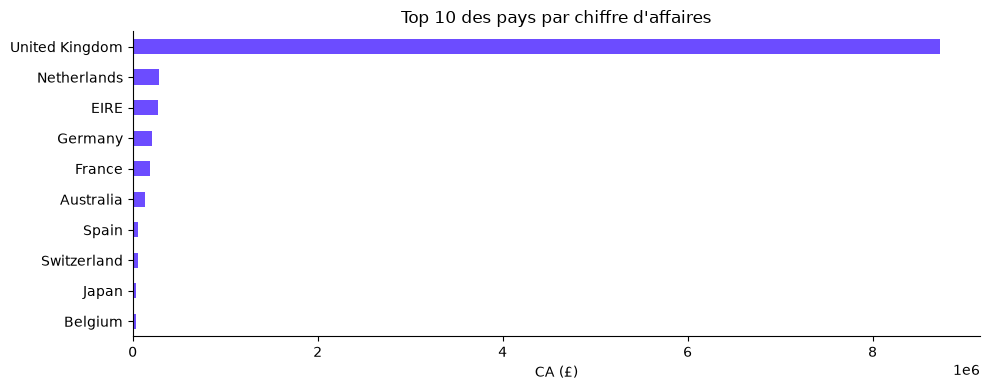

In [8]:
pays = ventes.groupby("Country")["Montant"].sum().sort_values(ascending=False)
print(f"Part du Royaume-Uni : {pays.iloc[0] / pays.sum():.1%}")
ax = pays.head(10).iloc[::-1].plot.barh(color=VIOLET)
ax.set(title="Top 10 des pays par chiffre d'affaires", xlabel="CA (£)", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "ca_par_pays.png", dpi=150); plt.show()

### Produits les plus vendus

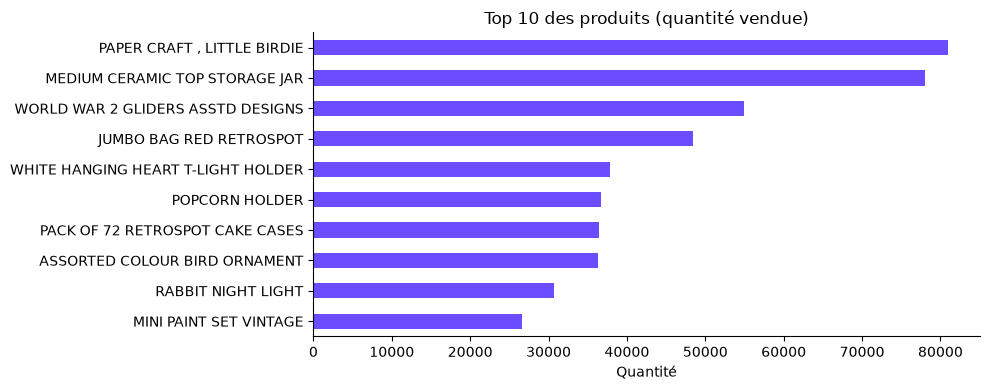

,quantite,ca
Description,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
JUMBO BAG RED RETROSPOT,48371,94159.81
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
POPCORN HOLDER,36749,34288.67
PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
RABBIT NIGHT LIGHT,30739,66870.03


In [9]:
top = (ventes.groupby("Description")
       .agg(quantite=("Quantity", "sum"), ca=("Montant", "sum"))
       .sort_values("quantite", ascending=False).head(10))
ax = top["quantite"].iloc[::-1].plot.barh(color=VIOLET)
ax.set(title="Top 10 des produits (quantité vendue)", xlabel="Quantité", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "top_produits.png", dpi=150); plt.show()
top

### Saisonnalité mensuelle
⚠️ Décembre 2011 est incomplet (le dataset s'arrête le 9).

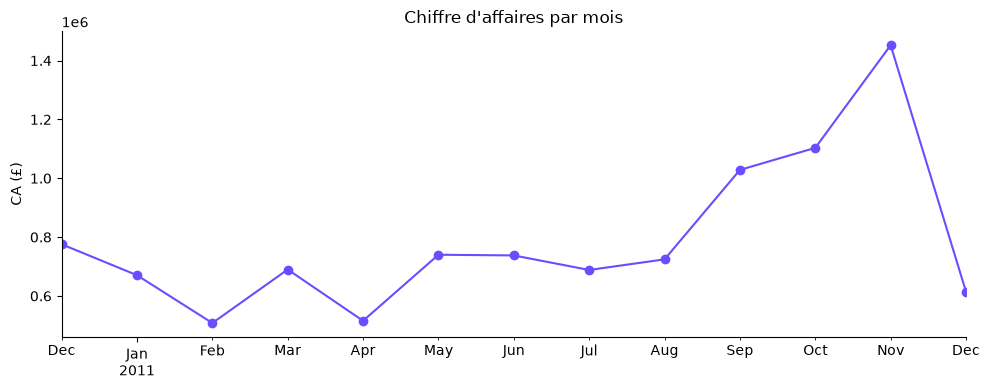

In [10]:
mois = ventes.set_index("InvoiceDate")["Montant"].resample("MS").sum()
ax = mois.plot(marker="o", color=VIOLET)
ax.set(title="Chiffre d'affaires par mois", xlabel="", ylabel="CA (£)")
plt.tight_layout(); plt.savefig(FIG / "ca_par_mois.png", dpi=150); plt.show()

### Jours et heures de pointe

C:\Users\leoni\AppData\Local\Temp\ipykernel_23416\2784812010.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  par_jour = ventes.groupby(ventes["InvoiceDate"].dt.dayofweek)["Montant"].sum().reindex(range(7), fill_value=0)


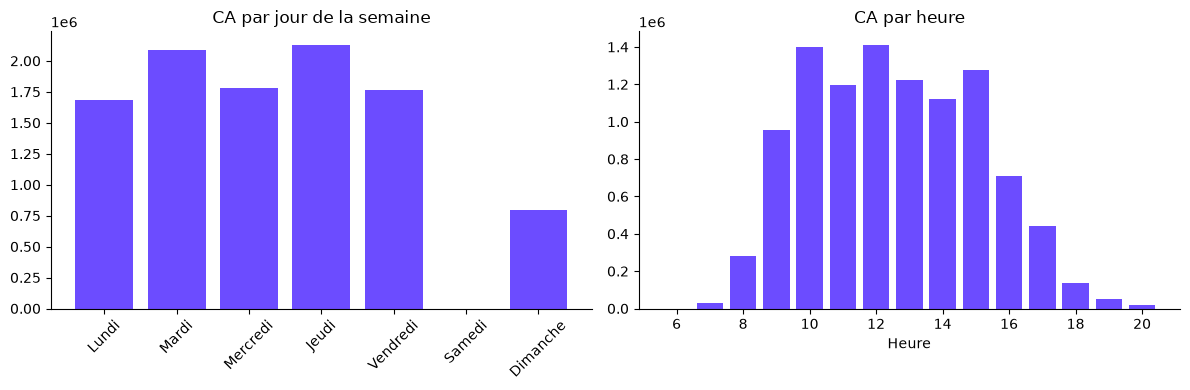

In [11]:
jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
par_jour = ventes.groupby(ventes["InvoiceDate"].dt.dayofweek)["Montant"].sum().reindex(range(7), fill_value=0)
par_heure = ventes.groupby(ventes["InvoiceDate"].dt.hour)["Montant"].sum()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(jours, par_jour.values, color=VIOLET); a1.set(title="CA par jour de la semaine"); a1.tick_params(axis="x", rotation=45)
a2.bar(par_heure.index, par_heure.values, color=VIOLET); a2.set(title="CA par heure", xlabel="Heure")
plt.tight_layout(); plt.savefig(FIG / "jours_heures.png", dpi=150); plt.show()

### Volume de transactions par minute (dimensionnement du flux)
Utile pour choisir la vitesse de rejeu et la taille des fenêtres Spark.

In [12]:
par_min = df.set_index("InvoiceDate").resample("1min").size()
par_min = par_min[par_min > 0]
par_min.describe().round(1)

count    21308.0
mean        24.9
std         46.9
min          1.0
25%          4.0
50%         13.0
75%         28.0
max       1113.0
dtype: float64

## Conclusions à reporter dans le rapport
- *(à compléter avec les vrais chiffres)* part du Royaume-Uni, pays suivants
- produits phares
- pic de ventes avant Noël (sept.–nov. 2011)
- jours et heures de pointe (pas de ventes le samedi dans ce dataset)